In [6]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
from pathlib import Path

# Dataset location
DATASET_DIR = Path(
    r"C:\Banana Sense-AI\data\raw\Banana Ripeness Detection Dataset"
)

# Check dataset
print("Dataset exists:", DATASET_DIR.exists())

if DATASET_DIR.exists():
    print("\nFolders inside dataset:")
    for folder in DATASET_DIR.iterdir():
        if folder.is_dir():
            print("-", folder.name)

Dataset exists: True

Folders inside dataset:
- Green
- Overripe
- Ripe
- Semi-ripe


In [8]:
import pandas as pd

# Supported image formats
image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

# Expected classes
expected_classes = ["Green", "Semi-ripe", "Ripe", "Overripe"]

class_counts = {}

for class_name in expected_classes:

    class_folder = DATASET_DIR / class_name

    if class_folder.exists():

        images = [
            file for file in class_folder.rglob("*")
            if file.suffix.lower() in image_extensions
        ]

        class_counts[class_name] = len(images)

    else:
        print(f"Folder not found: {class_name}")

# Create DataFrame
df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Ripeness Stage", "Image Count"]
)

display(df)

print("Total Images:", df["Image Count"].sum())

,Ripeness Stage,Image Count
0,Green,212
1,Semi-ripe,204
2,Ripe,201
3,Overripe,203


Total Images: 820


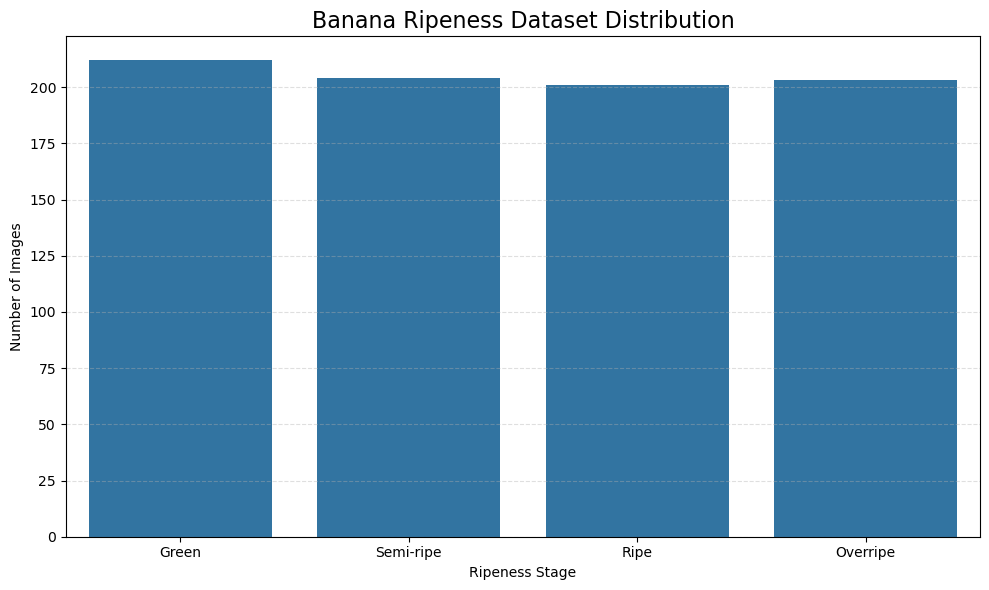

In [9]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Ripeness Stage",
    y="Image Count"
)

plt.title("Banana Ripeness Dataset Distribution", fontsize=16)
plt.xlabel("Ripeness Stage")
plt.ylabel("Number of Images")

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

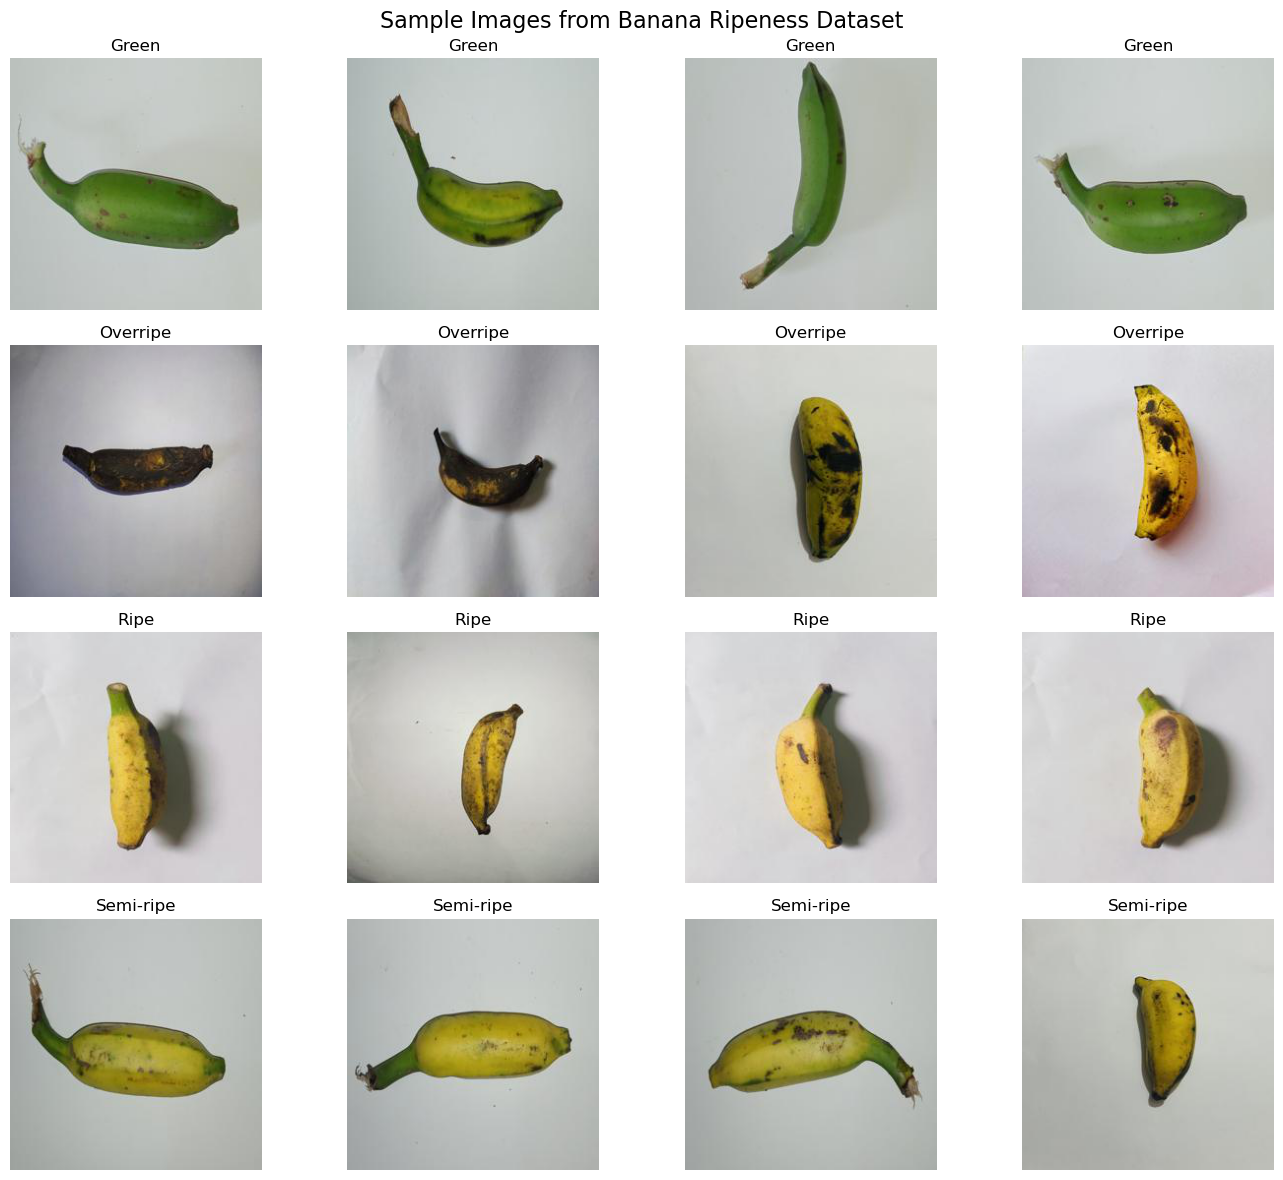

In [11]:
import random
from PIL import Image
import matplotlib.pyplot as plt

# Number of sample images per class
samples_per_class = 4

# Find all class folders
class_folders = sorted([
    folder for folder in DATASET_DIR.iterdir()
    if folder.is_dir()
])

# Create visualization grid
fig, axes = plt.subplots(
    len(class_folders),
    samples_per_class,
    figsize=(14, 12),
    squeeze=False
)

random.seed(42)

for row, class_folder in enumerate(class_folders):

    images = [
        file for file in class_folder.rglob("*")
        if file.suffix.lower() in image_extensions
    ]

    selected_images = random.sample(
        images,
        min(samples_per_class, len(images))
    )

    for col in range(samples_per_class):

        axes[row, col].axis("off")

        if col < len(selected_images):

            img = Image.open(
                selected_images[col]
            ).convert("RGB")

            axes[row, col].imshow(img)

            axes[row, col].set_title(
                class_folder.name
            )

plt.suptitle(
    "Sample Images from Banana Ripeness Dataset",
    fontsize=16
)

plt.tight_layout()
plt.show()

In [12]:
image_data = []

for class_folder in class_folders:

    for image_path in class_folder.rglob("*"):

        if image_path.suffix.lower() in image_extensions:

            try:
                with Image.open(image_path) as img:

                    width, height = img.size

                    image_data.append({
                        "Class": class_folder.name,
                        "Width": width,
                        "Height": height,
                        "Format": img.format
                    })

            except Exception:
                pass

image_df = pd.DataFrame(image_data)

print("Total images:", len(image_df))

print("\nAverage dimensions:")
print("Width:", image_df["Width"].mean())
print("Height:", image_df["Height"].mean())

display(image_df.head(10))

Total images: 820

Average dimensions:
Width: 255.95975609756098
Height: 255.9878048780488


,Class,Width,Height,Format
0,Green,256,256,JPEG
1,Green,256,256,JPEG
2,Green,256,256,JPEG
3,Green,256,256,JPEG
4,Green,256,256,JPEG
5,Green,256,256,JPEG
6,Green,256,256,JPEG
7,Green,256,256,JPEG
8,Green,256,256,JPEG
9,Green,256,256,JPEG


In [13]:
corrupted_images = []
valid_images = 0

for class_folder in class_folders:

    for image_path in class_folder.rglob("*"):

        if image_path.suffix.lower() in image_extensions:

            try:
                with Image.open(image_path) as img:
                    img.verify()

                valid_images += 1

            except Exception:
                corrupted_images.append(str(image_path))

print("Total valid images:", valid_images)
print("Total corrupted images:", len(corrupted_images))

if corrupted_images:
    print("\nCorrupted image files:")

    for image in corrupted_images[:10]:
        print(image)

Total valid images: 820
Total corrupted images: 0


In [14]:
import hashlib
from collections import defaultdict

image_hashes = defaultdict(list)

for class_folder in class_folders:

    for image_path in class_folder.rglob("*"):

        if image_path.suffix.lower() in image_extensions:

            try:
                with open(image_path, "rb") as file:
                    image_hash = hashlib.sha256(file.read()).hexdigest()

                image_hashes[image_hash].append(str(image_path))

            except Exception:
                pass

duplicates = {
    key: paths
    for key, paths in image_hashes.items()
    if len(paths) > 1
}

print("Duplicate groups:", len(duplicates))
print(
    "Total files involved in duplicates:",
    sum(len(paths) for paths in duplicates.values())
)

Duplicate groups: 1
Total files involved in duplicates: 2


In [15]:
for group_number, (image_hash, paths) in enumerate(duplicates.items(), 1):

    print(f"\nDuplicate Group {group_number}")

    for path in paths:
        image_path = Path(path)

        print("File:", image_path.name)
        print("Class:", image_path.parent.name)
        print("Location:", image_path)


Duplicate Group 1
File: Ripe_6.jpg
Class: Ripe
Location: C:\Banana Sense-AI\data\raw\Banana Ripeness Detection Dataset\Ripe\Ripe_6.jpg
File: Semi_ripe_81.jpg
Class: Semi-ripe
Location: C:\Banana Sense-AI\data\raw\Banana Ripeness Detection Dataset\Semi-ripe\Semi_ripe_81.jpg


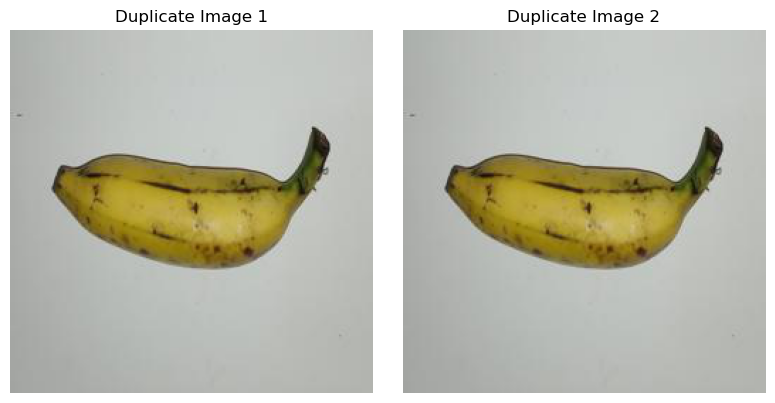

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

duplicate_paths = list(duplicates.values())[0]

for i, path in enumerate(duplicate_paths):

    img = Image.open(path).convert("RGB")

    axes[i].imshow(img)
    axes[i].set_title(f"Duplicate Image {i+1}")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

In [17]:
for paths in duplicates.values():

    for path in paths:
        image_path = Path(path)

        print("Filename:", image_path.name)
        print("Class:", image_path.parent.name)
        print("Path:", image_path)

        print("-" * 50)

Filename: Ripe_6.jpg
Class: Ripe
Path: C:\Banana Sense-AI\data\raw\Banana Ripeness Detection Dataset\Ripe\Ripe_6.jpg
--------------------------------------------------
Filename: Semi_ripe_81.jpg
Class: Semi-ripe
Path: C:\Banana Sense-AI\data\raw\Banana Ripeness Detection Dataset\Semi-ripe\Semi_ripe_81.jpg
--------------------------------------------------


In [18]:
from pathlib import Path

# Image to delete
duplicate_to_delete = (
    DATASET_DIR / "Semi-ripe" / "Semi_ripe_81.jpg"
)

# Delete the duplicate
if duplicate_to_delete.exists():
    duplicate_to_delete.unlink()
    print("Deleted successfully:", duplicate_to_delete.name)
else:
    print("File not found!")

Deleted successfully: Semi_ripe_81.jpg


In [19]:
from sklearn.model_selection import train_test_split
import pandas as pd

image_extensions = {".jpg", ".jpeg", ".png", ".webp"}

records = []

for class_folder in sorted(DATASET_DIR.iterdir()):

    if class_folder.is_dir():

        for image_path in class_folder.rglob("*"):

            if image_path.suffix.lower() in image_extensions:

                records.append({
                    "image_path": str(image_path.resolve()),
                    "label": class_folder.name
                })

dataset_df = pd.DataFrame(records)

print("Total images:", len(dataset_df))
print("\nClass distribution:")
print(dataset_df["label"].value_counts())

Total images: 819

Class distribution:
label
Green        212
Overripe     203
Semi-ripe    203
Ripe         201
Name: count, dtype: int64


In [20]:
# 70% Training and 30% Temporary
train_df, temp_df = train_test_split(
    dataset_df,
    test_size=0.30,
    stratify=dataset_df["label"],
    random_state=42
)

# Divide temporary data equally
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    stratify=temp_df["label"],
    random_state=42
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 573
Validation images: 123
Testing images: 123


In [21]:
split_distribution = pd.DataFrame({
    "Training": train_df["label"].value_counts(),
    "Validation": val_df["label"].value_counts(),
    "Testing": test_df["label"].value_counts()
}).fillna(0).astype(int)

display(split_distribution)

,Training,Validation,Testing
label,,,
Green,148,32,32
Overripe,142,30,31
Ripe,141,30,30
Semi-ripe,142,31,30


In [22]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

train_df.assign(split="train").to_csv(
    PROCESSED_DIR / "train.csv", index=False
)

val_df.assign(split="validation").to_csv(
    PROCESSED_DIR / "validation.csv", index=False
)

test_df.assign(split="test").to_csv(
    PROCESSED_DIR / "test.csv", index=False
)

print("Dataset splits saved successfully!")
print("Location:", PROCESSED_DIR)

Dataset splits saved successfully!
Location: c:\Banana Sense-AI\data\processed


In [23]:
import pandas as pd

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "validation.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTotal images:", len(train_df) + len(val_df) + len(test_df))

print("\nTraining distribution:")
print(train_df["label"].value_counts())

print("\nValidation distribution:")
print(val_df["label"].value_counts())

print("\nTesting distribution:")
print(test_df["label"].value_counts())

Training images: 573
Validation images: 123
Testing images: 123

Total images: 819

Training distribution:
label
Green        148
Semi-ripe    142
Overripe     142
Ripe         141
Name: count, dtype: int64

Validation distribution:
label
Green        32
Semi-ripe    31
Ripe         30
Overripe     30
Name: count, dtype: int64

Testing distribution:
label
Green        32
Overripe     31
Ripe         30
Semi-ripe    30
Name: count, dtype: int64


In [24]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU available: []


In [25]:
from pathlib import Path

PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

train_df = pd.read_csv(PROCESSED_DIR / "train.csv")
val_df = pd.read_csv(PROCESSED_DIR / "validation.csv")
test_df = pd.read_csv(PROCESSED_DIR / "test.csv")

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

Training images: 573
Validation images: 123
Testing images: 123


In [26]:
IMG_SIZE = 128
BATCH_SIZE = 16

print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)

Image size: 128
Batch size: 16


In [27]:
class_names = sorted(train_df["label"].unique())

label_to_id = {
    name: index
    for index, name in enumerate(class_names)
}

id_to_label = {
    index: name
    for name, index in label_to_id.items()
}

print("Class mapping:")

for name, index in label_to_id.items():
    print(name, ":", index)

Class mapping:
Green : 0
Overripe : 1
Ripe : 2
Semi-ripe : 3


In [28]:
def preprocess_image(image_path, label):

    # Read image
    image = tf.io.read_file(image_path)

    # Decode image
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    # Resize image
    image = tf.image.resize(
        image,
        [IMG_SIZE, IMG_SIZE]
    )

    # Normalize pixel values
    image = image / 255.0

    return image, label

In [29]:
def create_dataset(dataframe, training=False):

    paths = dataframe["image_path"].values

    labels = dataframe["label"].map(
        label_to_id
    ).values.astype("int32")

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    # Shuffle training images
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=42
        )

    # Apply preprocessing
    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=2
    )

    # Process images in batches
    dataset = dataset.batch(BATCH_SIZE)

    # Prefetch one batch
    dataset = dataset.prefetch(1)

    return dataset


train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training dataset created!")
print("Validation dataset created!")
print("Testing dataset created!")

Training dataset created!
Validation dataset created!
Testing dataset created!


In [30]:
images, labels = next(iter(train_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

print(
    "Minimum pixel value:",
    tf.reduce_min(images).numpy()
)

print(
    "Maximum pixel value:",
    tf.reduce_max(images).numpy()
)

Image batch shape: (16, 128, 128, 3)
Label batch shape: (16,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


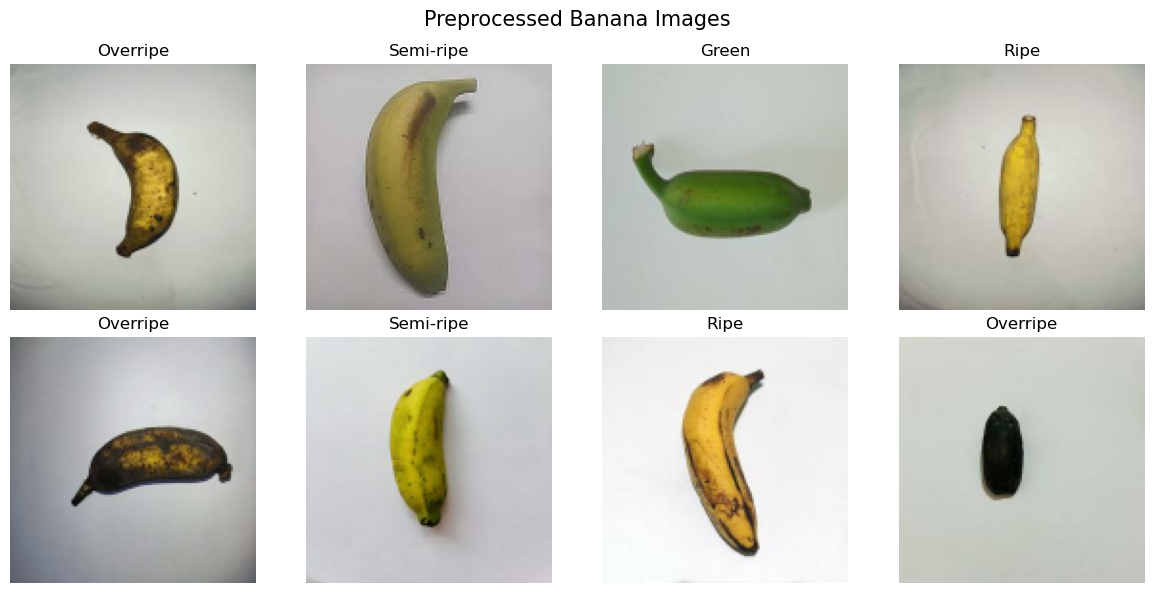

In [31]:
plt.figure(figsize=(12, 6))

for i in range(min(8, len(images))):

    plt.subplot(2, 4, i + 1)

    plt.imshow(images[i].numpy())

    label_id = labels[i].numpy()

    plt.title(id_to_label[label_id])
    plt.axis("off")

plt.suptitle("Preprocessed Banana Images", fontsize=15)

plt.tight_layout()
plt.show()

In [32]:
print("Training images:", len(train_df))
print("Training batches:", len(train_ds))

print("Validation images:", len(val_df))
print("Validation batches:", len(val_ds))

print("Testing images:", len(test_df))
print("Testing batches:", len(test_ds))

Training images: 573
Training batches: 36
Validation images: 123
Validation batches: 8
Testing images: 123
Testing batches: 8
